In [18]:
!pip install rdkit
import pandas as pd
import numpy as np
from rdkit import Chem

In [19]:
df = pd.read_csv("DB for chromophore_Sci_Data_rev02.csv", encoding="utf-8-sig")
print(df.shape)
print(df.columns.tolist())
df.head()

(20236, 14)
['Tag', 'Chromophore', 'Solvent', 'Absorption max (nm)', 'Emission max (nm)', 'Lifetime (ns)', 'Quantum yield', 'log(e/mol-1 dm3 cm-1)', 'abs FWHM (cm-1)', 'emi FWHM (cm-1)', 'abs FWHM (nm)', 'emi FWHM (nm)', 'Molecular weight (g mol-1)', 'Reference']


,Tag,Chromophore,Solvent,Absorption max (nm),Emission max (nm),Lifetime (ns),Quantum yield,log(e/mol-1 dm3 cm-1),abs FWHM (cm-1),emi FWHM (cm-1),abs FWHM (nm),emi FWHM (nm),Molecular weight (g mol-1),Reference
0,1,N#Cc1cc2ccc(O)cc2oc1=O,O,355.0,410.00,2.804262,NaN,NaN,NaN,NaN,NaN,NaN,187.15370,DOI: 10.1021/acs.jpcb.5b09905
1,2,N#Cc1cc2ccc([O-])cc2oc1=O,O,408.0,450.00,3.961965,NaN,NaN,NaN,NaN,NaN,43.0,186.14576,DOI: 10.1021/acs.jpcb.5b09905
2,3,CCCCCCCCCCCC#CC#CCCCCCCCCCN1C(=O)c2ccc3c4ccc5c...,ClC(Cl)Cl,526.0,535.00,3.602954,NaN,NaN,NaN,NaN,NaN,NaN,1061.54348,https://doi.org/10.1002/smll.201901342
3,4,[O-]c1c(-c2nc3ccccc3s2)cc2ccc3cccc4ccc1c2c34,CC#N,514.0,553.72,3.810000,NaN,NaN,NaN,NaN,NaN,67.4,350.42028,https://doi.org/10.1016/j.snb.2018.10.043
4,5,[O-]c1c(-c2nc3ccccc3s2)cc2ccc3cccc4ccc1c2c34,CS(C)=O,524.0,555.00,4.700000,NaN,NaN,NaN,NaN,58.0,50.0,350.42028,https://doi.org/10.1016/j.snb.2018.10.043


In [20]:
df.notna().sum()

,0
Tag,20236
Chromophore,20236
Solvent,20236
Absorption max (nm),17295
Emission max (nm),18142
Lifetime (ns),6960
Quantum yield,13837
log(e/mol-1 dm3 cm-1),8041
abs FWHM (cm-1),747
emi FWHM (cm-1),627


In [21]:
df = df.dropna(subset=["Emission max (nm)"])
print(len(df))

18142


In [22]:
df = df[df["Solvent"] != "gas"]

In [23]:
def canon(smi):
    mol = Chem.MolFromSmiles(smi)
    return Chem.MolToSmiles(mol) if mol is not None else None

df["chrom"] = df["Chromophore"].apply(canon)
df["solv"] = df["Solvent"].apply(canon)

print("unparsable:", df["chrom"].isna().sum(), df["solv"].isna().sum())
print("unique solvents before:", df["Solvent"].nunique(), "after:", df["solv"].nunique())

unparsable: 0 0
unique solvents before: 1021 after: 1021


In [24]:
counts = df.groupby(["chrom", "solv"]).size()
print((counts > 1).sum(), "pairs measured more than once")
dup = counts[counts > 1].index[0]
df[(df.chrom == dup[0]) & (df.solv == dup[1])][["Emission max (nm)", "Reference"]]

284 pairs measured more than once


,Emission max (nm),Reference
4066,486.0,https://doi.org/10.1016/j.molliq.2019.04.058
19256,482.0,DOI: 10.1021/jo300724m


In [25]:
clean = df.groupby(["chrom", "solv"], as_index=False).agg(
    emi_nm=("Emission max (nm)", "mean"),
    abs_nm=("Absorption max (nm)", "mean"),
    qy=("Quantum yield", "mean"),
    n_meas=("Emission max (nm)", "size"),
)
clean["emi_eV"] = 1239.84 / clean["emi_nm"]
print(clean.shape, clean.chrom.nunique())

(17850, 7) 6412


In [26]:
clean.to_csv("my_data_clean.csv", index=False)

In [27]:
df = pd.read_csv("my_data_clean.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(17850, 7)
['chrom', 'solv', 'emi_nm', 'abs_nm', 'qy', 'n_meas', 'emi_eV']


,chrom,solv,emi_nm,abs_nm,qy,n_meas,emi_eV
0,B1C=Cc2ccc3ccccc3c2N1,C1CCCCC1,371.0,351.0,0.6100,1,3.341887
1,BrC1=CC=CN2B1C=Cc1ccccc12,C1CCCCC1,371.0,300.0,0.0049,1,3.341887
2,BrC1=CN2C[n+]3cc(Br)c4ccccc4c3N=C2c2ccccc21,CO,502.0,457.0,NaN,1,2.469801
3,BrC1=CN2C[n+]3cc(Br)cc(Br)c3N=C2C(Br)=C1,CS(C)=O,494.0,449.0,NaN,1,2.509798
4,BrC1=CN2C[n+]3cc(Br)ccc3N=C2C=C1,CO,476.0,434.0,NaN,1,2.604706


C#Cc1ccc2ccc3cccc4ccc1c2c34
c1cc2ccc3cccc4ccc(c1)c2c34


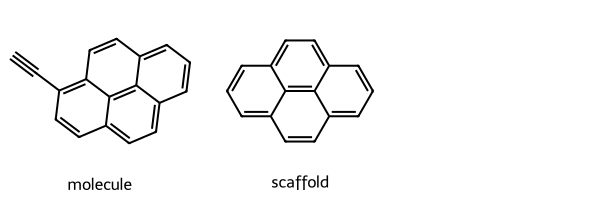

In [28]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw

smi = clean.chrom.iloc[100]
scaf = MurckoScaffold.MurckoScaffoldSmiles(smiles=smi)
print(smi)
print(scaf)
Draw.MolsToGridImage([Chem.MolFromSmiles(smi), Chem.MolFromSmiles(scaf)], legends=["molecule", "scaffold"])

In [29]:
def scaffold(smi):
    s = MurckoScaffold.MurckoScaffoldSmiles(smiles=smi)
    return s if s else smi   # molecules with no rings: use the molecule itself

clean["scaffold"] = clean["chrom"].apply(scaffold)
print(clean.scaffold.nunique(), "unique scaffolds")
clean.scaffold.value_counts().head(10)

3345 unique scaffolds


,count
scaffold,
c1ccccc1,388
[BH2-]1n2cccc2C(c2ccccc2)=C2C=CC=[N+]12,229
c1cc2ccc3cccc4ccc(c1)c2c34,202
[BH2-]1n2cccc2C=C2C=CC=[N+]12,177
c1ccc2ccccc2c1,132
O=c1ccc2ccccc2o1,117
C(#Cc1ccccc1)c1ccccc1,106
O=C1Nc2ccccc2C1=CC(=O)c1ccccc1,94
c1ccc(-c2nc3ccccc3s2)cc1,87


In [30]:
groups = clean.groupby("scaffold").size().sample(frac=1, random_state=42)  # shuffle scaffolds
big = groups[groups > len(clean) * 0.005].index.tolist()   # very large families → train
small = [g for g in groups.index if g not in set(big)]

split, count, n = {}, 0, len(clean)
for g in big + small:
    if count < 0.8 * n:
        split[g] = "train"
    elif count < 0.9 * n:
        split[g] = "val"
    else:
        split[g] = "test"
    count += groups[g]

clean["split"] = clean.scaffold.map(split)
clean.split.value_counts()

,count
split,
train,14281
val,1790
test,1779


In [31]:
train_s = set(clean[clean.split == "train"].scaffold)
test_s = set(clean[clean.split == "test"].scaffold)
print("shared scaffolds:", len(train_s & test_s))   # must be 0

clean.groupby("split").apply(lambda d: (d.emi_nm >= 700).sum())

shared scaffolds: 0


/tmp/ipykernel_872/3848754064.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  clean.groupby("split").apply(lambda d: (d.emi_nm >= 700).sum())


,0
split,
test,77
train,475
val,64


In [34]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

clean.to_csv("/content/drive/MyDrive/NIR_Thesis/Data/my_data_clean.csv", index=False)

Mounted at /content/drive


In [36]:
pd.read_csv("/content/drive/MyDrive/NIR_Thesis/Data/my_data_clean.csv").shape

(17850, 9)

In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
